# Notebook de Modelagem e Teste dos Dados

Neste notebook será realizada a etapa de avaliação dos dados já preparados no notebook de preparação (`data_prep.ipynb`).

Aqui vamos testar o desempenho dos nossos dados com **Random Forest** como modelo inicial de referência, por ser uma abordagem robusta e eficiente para classificação. A ideia é verificar se, com as features já tratadas, normalizadas e separadas em treino, validação e teste, conseguimos obter uma boa acurácia e um comportamento consistente na predição das classes de Libras.

Caso a acurácia do Random Forest não seja satisfatória, ou se houver espaço para melhoria, partiremos para o **XGBoost**, que costuma oferecer maior poder de ajuste e melhor desempenho em problemas de classificação mais complexos.

O foco deste notebook é comparar o desempenho dos modelos, validar os resultados com métricas adequadas e escolher a estratégia mais eficiente para a etapa final da pipeline.

## Fluxo passo a passo

1. **Carregar os dados já preparados**
   - Utilizar os arquivos gerados no `data_prep.ipynb`, como `train.csv`, `validation.csv` e `test.csv`.
   - Garantir que as features estejam padronizadas e prontas para treinamento.

2. **Entender a base final de entrada**
   - Conferir o formato dos dados.
   - Separar corretamente variáveis de entrada (`X`) e rótulo alvo (`y`).

3. **Treinar um modelo base com Random Forest**
   - Usar o conjunto de treino para ajustar o modelo.
   - Avaliar o resultado inicial na validação.

4. **Medir a performance com métricas de classificação**
   - Verificar acurácia, matriz de confusão e outras métricas relevantes.
   - Analisar se o modelo está generalizando bem.

5. **Decidir o próximo modelo com base no resultado**
   - Se a acurácia do Random Forest for boa, seguir com ele como solução principal.
   - Se o resultado ficar abaixo do esperado, testar o **XGBoost** como alternativa mais forte.

6. **Comparar Random Forest e XGBoost**
   - Avaliar qual modelo apresenta melhor desempenho geral.
   - Considerar não apenas acurácia, mas também equilíbrio entre classes e robustez.

7. **Validar o modelo escolhido no conjunto de teste**
   - Fazer a avaliação final apenas após a escolha do melhor modelo.
   - Registrar os resultados para uso na pipeline.

8. **Salvar conclusões e próximos passos**
   - Documentar o modelo selecionado.
   - Indicar possíveis melhorias futuras na preparação dos dados ou no ajuste de hiperparâmetros.

### Imports

In [40]:
#Visualização 
import matplotlib.pyplot as plt
import seaborn as sns


#Organização dos dados
import pandas as pd 
from pathlib import Path

#Modelos
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report, ConfusionMatrixDisplay


#Caminhos dos dados
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PREPARED_DATA_DIR = PROJECT_ROOT / "data" / "data_output" / "prepared"

train_path = PREPARED_DATA_DIR / "train.csv"
test_path = PREPARED_DATA_DIR / "test.csv"
validate_path = PREPARED_DATA_DIR / "validation.csv"

### 1. Carregar Dados de Treino Já preparados

In [41]:
train_df = pd.read_csv(train_path)

train_df

,label,x0,y0,z0,x1,y1,z1,x2,y2,z2,...,dist_indicador_medio_pip,dist_indicador_medio_mcp,dist_polegar_minimo_pontas,dist_polegar_indicador_pontas,dist_polegar_indicador_mcp,dist_polegar_indicador_pip,dist_polegar_indicador_dip,dist_polegar_indicador_tip,dist_indicador_anelar_pontas,dist_medio_anelar_pontas
0,F,0.0,0.0,0.0,-0.677623,-0.301028,0.317427,-0.567458,-0.373401,0.533034,...,0.504473,0.051890,0.024555,-1.577269,-1.224346,-1.144886,-1.411355,-1.577269,0.211346,-0.383229
1,A,0.0,0.0,0.0,-1.250467,0.441103,-1.845972,-1.426928,-0.209762,-1.761458,...,0.254906,1.620718,1.351806,0.575799,1.244096,1.304333,0.856537,0.575799,-0.463513,-0.148992
2,O,0.0,0.0,0.0,-1.255528,-0.228857,0.756359,-0.964644,-0.273885,0.576929,...,-1.451722,-1.867114,-1.227714,-1.184404,1.786885,0.779503,-0.249785,-1.184404,-1.640042,-0.824661
3,L,0.0,0.0,0.0,-0.482106,0.286116,-0.041535,-0.654397,0.135690,-0.155060,...,0.860101,-0.432978,0.280166,1.676083,0.810498,1.240257,1.625535,1.676083,1.218623,-0.655175
4,O,0.0,0.0,0.0,-1.282456,0.520329,1.102954,-1.334052,0.307999,1.042759,...,-0.344083,-0.183919,-0.755108,-1.602388,0.634172,0.347592,-0.707011,-1.602388,-1.476490,-0.757466
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19097,L,0.0,0.0,0.0,-0.516028,0.405059,-0.229214,-0.668147,0.274592,-0.258754,...,0.325566,-0.423852,0.348862,2.096429,0.853865,1.513544,1.994108,2.096429,1.437080,-0.676149
19098,V,0.0,0.0,0.0,-0.200469,-0.181724,-0.434875,-0.072844,-0.148756,-0.438236,...,0.639708,-0.449819,-1.148121,1.070814,-0.407463,0.408772,0.894374,1.070814,0.973048,1.792683
19099,S,0.0,0.0,0.0,1.759438,0.283400,-1.938952,2.007819,-0.149731,-1.844567,...,1.328926,2.445467,-0.224581,-0.819432,0.427102,1.189848,-0.196648,-0.819432,-0.088421,-0.110595
19100,E,0.0,0.0,0.0,-0.565190,-0.021407,-0.085322,-0.660505,-0.212885,-0.090350,...,-0.890148,-0.205339,-0.345483,-1.011253,-0.443499,0.938901,-0.130833,-1.011253,-0.924532,-0.608216


In [42]:
def preparar_features_e_alvo(df, label_column="label", indices_selecionados=None):
    if indices_selecionados is None:
        indices_selecionados = list(range(21)) #todas as colunas de marcações de pontos 

    colunas_landmarks = [
        f"{dim}{idx}"
        for idx in indices_selecionados
        for dim in ("x", "y", "z")
    ]

    colunas_dist = [col for col in df.columns if "dist" in col.lower()]

    colunas_selecionadas = []
    for col in colunas_landmarks + colunas_dist:
        if col in df.columns and col not in colunas_selecionadas:
            colunas_selecionadas.append(col)

    x = df[colunas_selecionadas].copy()
    y = df[label_column].copy()

    return x, y, colunas_selecionadas

In [43]:
x_train, y_train, colunas_selecionadas = preparar_features_e_alvo(train_df)

print("Colunas selecionadas:", colunas_selecionadas)
print("Classe alvo (y):", y_train.name)

x_train.head()

Colunas selecionadas: ['x0', 'y0', 'z0', 'x1', 'y1', 'z1', 'x2', 'y2', 'z2', 'x3', 'y3', 'z3', 'x4', 'y4', 'z4', 'x5', 'y5', 'z5', 'x6', 'y6', 'z6', 'x7', 'y7', 'z7', 'x8', 'y8', 'z8', 'x9', 'y9', 'z9', 'x10', 'y10', 'z10', 'x11', 'y11', 'z11', 'x12', 'y12', 'z12', 'x13', 'y13', 'z13', 'x14', 'y14', 'z14', 'x15', 'y15', 'z15', 'x16', 'y16', 'z16', 'x17', 'y17', 'z17', 'x18', 'y18', 'z18', 'x19', 'y19', 'z19', 'x20', 'y20', 'z20', 'dist_polegar_pulso', 'dist_indicador_pulso', 'dist_medio_pulso', 'dist_anelar_pulso', 'dist_minimo_pulso', 'dist_indicador_medio_pontas', 'dist_indicador_medio_pip', 'dist_indicador_medio_mcp', 'dist_polegar_minimo_pontas', 'dist_polegar_indicador_pontas', 'dist_polegar_indicador_mcp', 'dist_polegar_indicador_pip', 'dist_polegar_indicador_dip', 'dist_polegar_indicador_tip', 'dist_indicador_anelar_pontas', 'dist_medio_anelar_pontas']
Classe alvo (y): label


,x0,y0,z0,x1,y1,z1,x2,y2,z2,x3,...,dist_indicador_medio_pip,dist_indicador_medio_mcp,dist_polegar_minimo_pontas,dist_polegar_indicador_pontas,dist_polegar_indicador_mcp,dist_polegar_indicador_pip,dist_polegar_indicador_dip,dist_polegar_indicador_tip,dist_indicador_anelar_pontas,dist_medio_anelar_pontas
0,0.0,0.0,0.0,-0.677623,-0.301028,0.317427,-0.567458,-0.373401,0.533034,-0.265521,...,0.504473,0.051890,0.024555,-1.577269,-1.224346,-1.144886,-1.411355,-1.577269,0.211346,-0.383229
1,0.0,0.0,0.0,-1.250467,0.441103,-1.845972,-1.426928,-0.209762,-1.761458,-1.660511,...,0.254906,1.620718,1.351806,0.575799,1.244096,1.304333,0.856537,0.575799,-0.463513,-0.148992
2,0.0,0.0,0.0,-1.255528,-0.228857,0.756359,-0.964644,-0.273885,0.576929,-1.070024,...,-1.451722,-1.867114,-1.227714,-1.184404,1.786885,0.779503,-0.249785,-1.184404,-1.640042,-0.824661
3,0.0,0.0,0.0,-0.482106,0.286116,-0.041535,-0.654397,0.135690,-0.155060,-0.887733,...,0.860101,-0.432978,0.280166,1.676083,0.810498,1.240257,1.625535,1.676083,1.218623,-0.655175
4,0.0,0.0,0.0,-1.282456,0.520329,1.102954,-1.334052,0.307999,1.042759,-1.527087,...,-0.344083,-0.183919,-0.755108,-1.602388,0.634172,0.347592,-0.707011,-1.602388,-1.476490,-0.757466


### Execução no terminal

```bash
# 1. Definimos o "espaço de busca" (as opções que queremos testar)
param_dist = {
    'n_estimators': [50, 100, 200, 300, 500],       # Número de árvores
    'max_depth': [None, 5, 10, 20, 30],             # Profundidade máxima
    'min_samples_split': [2, 5, 10],                # Mínimo de amostras para dividir um nó
    'min_samples_leaf': [1, 2, 4],                  # Mínimo de amostras em cada folha
    'max_features': ['sqrt', 'log2', None]         # Quantidade de colunas testadas por árvore
}

# 2. Instanciamos o modelo base
rf = RandomForestClassifier(random_state=42, n_jobs=-1)

# 3. Configuramos a busca aleatória
# n_iter=20 significa que ele vai testar 20 combinações aleatórias das opções acima
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=20,
    cv=5,               # Validação cruzada em 5 partes (folds)
    random_state=42,
    n_jobs=-1,          # Usa todo o processador
    scoring='accuracy'  # Métrica de escolha (pode ser 'f1', 'roc_auc', etc.)
)

# 4. Rodamos a busca nos dados de treino
random_search.fit(x_train, y_train)

# --- RESULTADOS ---
print("🏆 Melhores Parâmetros Encontrados:")
print(random_search.best_params_)

saida: 

{'n_estimators': 100, 
 'min_samples_split': 2, 
 'min_samples_leaf': 1, 
 'max_features': 'sqrt', 
 'max_depth': 30}
```

In [44]:
#Definição do Modelo e dos parâmetros
model = RandomForestClassifier(
    n_estimators=100,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    max_depth= 30,
    
)

In [45]:
#Treinamento do Modelo
model.fit(x_train,y_train)
print("Treinamento Conluido")

Treinamento Conluido


In [46]:
#Carrega dataset de teste
test_df = pd.read_csv(test_path)

# Usa as mesmas colunas selecionadas no treino
x_test = test_df[colunas_selecionadas].copy()
y_test = test_df["label"].copy()



In [47]:
#Teste do modelo
y_pred = model.predict(x_test)

print("Resultados no conjunto de teste")
print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}")
print(f"F1-score macro: {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"Recall macro: {recall_score(y_test, y_pred, average='macro'):.4f}")



Resultados no conjunto de teste
Acurácia: 0.9196
F1-score macro: 0.9176
Recall macro: 0.9286


In [48]:
print("\nRelatório por classe:")
print(classification_report(y_test, y_pred))


Relatório por classe:
              precision    recall  f1-score   support

           A       0.86      0.99      0.92       272
           B       0.98      0.99      0.98       160
           C       1.00      1.00      1.00       149
           D       0.99      1.00      1.00       146
           E       0.99      0.95      0.97       166
           F       0.99      0.78      0.87       400
           G       1.00      1.00      1.00       146
           I       0.87      0.99      0.93       145
           L       0.99      1.00      0.99       178
           M       0.69      0.96      0.81       151
           N       0.96      0.61      0.74       158
           O       1.00      1.00      1.00       178
           P       0.97      0.97      0.97       171
           Q       0.99      1.00      0.99       147
           R       0.81      0.73      0.77       164
           S       0.99      0.97      0.98       398
           T       0.61      0.99      0.76       147
    

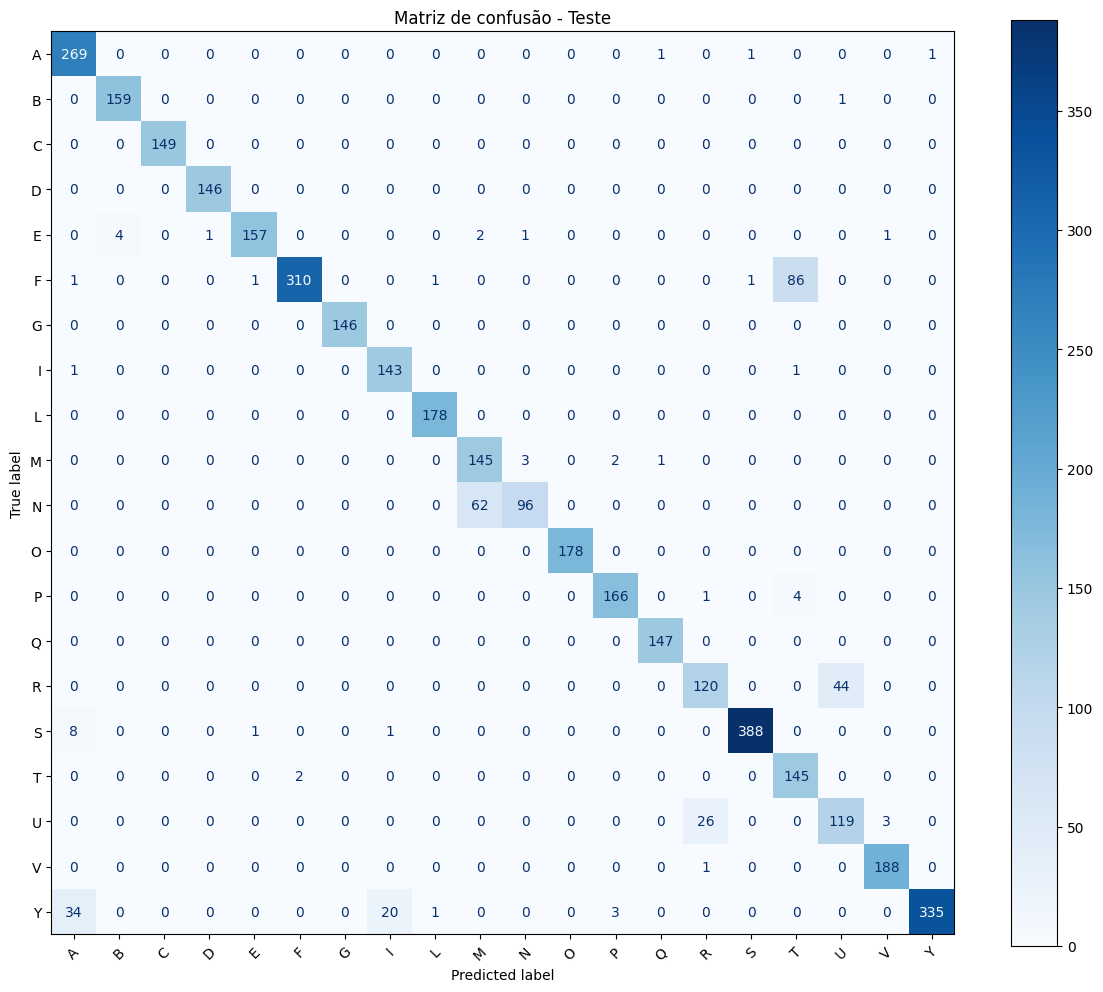

In [49]:
fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_estimator(
    model,
    x_test,
    y_test,
    labels=sorted(y_test.unique()),
    cmap="Blues",
    xticks_rotation=45,
    ax=ax,
)

plt.title("Matriz de confusão - Teste")
plt.tight_layout()
plt.show()